## checking dynamical conditions and sst patterns during max and min phases of individual regions

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [6]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

### load data

In [9]:
precip_obs = xr.open_mfdataset('/g/data/if69/as8561/data/obs_local/gpcc_v2020/precip.mon.total.1x1.v2020.nc').precip.load()
precip_obs

<xarray.DataArray 'precip' (time: 1548, lat: 180, lon: 360)>
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 1891-01-01 1891-02-01 ... 2019-12-01
Attributes:
    long_name:     GPCC Monthly total of precipitation
    statistic:     Total
    valid_range:   [   0. 8000.]
    parent_stat:   Observations
    var_desc:      Precipitation
    units:         mm
    level:         Surface
    dataset:       GPCC Precipitation 1.0degree V2020 Full Reanalysis
    actual_range:  [   0.   4830.39]

In [10]:
ts_obs_anom = xr.open_dataset('/g/data/if69/as8561/data/obs_local/HadCRUT.5.0.1.0.analysis.anomalies.ensemble_mean.nc').tas_mean.rename(dict(longitude='lon', latitude='lat'))
ts_obs_anom

<xarray.DataArray 'tas_mean' (time: 2079, lat: 36, lon: 72)>
[5388768 values with dtype=float64]
Coordinates:
  * time         (time) datetime64[ns] 1850-01-16T12:00:00 ... 2023-03-16T12:...
  * lat          (lat) float64 -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon          (lon) float64 -177.5 -172.5 -167.5 -162.5 ... 167.5 172.5 177.5
    realization  int64 ...
Attributes:
    long_name:     blended air_temperature_anomaly over land with sea_water_t...
    units:         K
    cell_methods:  area: mean (interval: 5.0 degrees_north 5.0 degrees_east) ...

In [11]:
precip_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/precip/prate.mon.mean.nc')

In [12]:
sst_obs = xc.open_dataset('/g/data/if69/as8561/data/obs_local/sst_obs.nc', lon_orient=(0,360)).sst
sst_obs = sst_obs.rename(dict(latitude='lat', longitude='lon'))
sst_obs

<xarray.DataArray 'sst' (time: 1837, lat: 180, lon: 361)>
array([[[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        ...,
...
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. ,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8, -1000. , ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. ,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]]],
      dtype=float32)
Coordinates:
  * time     (time) object 1870-01-16 11:59:59.505615 ... 2023-01-16 12:00:00
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5 359.5
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      sst
    units:          C
    cell_methods:   time: lat: lon: mean

In [13]:
sst_obs_anom = funcs.calc_anom(sst_obs, sst_obs.sel(time = slice('1960', '1990')))
# sst_obs_anom = sst_obs_anom.sel(time = sst_obs_anom.time.dt.month.isin([9,10,11,12,1,2])).resample(time='AS-JUN').mean('time')
sst_obs_anom = sst_obs_anom.resample(time='AS-JUN').mean('time')
weights_sst_obs = np.cos(np.deg2rad(sst_obs.lat))
nino34_obs = funcs.detrend_separate_check(sst_obs_anom.sel(lat=slice(5,-5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [14]:
precip_obs_anom = funcs.calc_anom(precip_obs, precip_obs.sel(time = slice('1960', '1990')))
# precip_obs_anom = precip_obs_anom.sel(time = precip_obs_anom.time.dt.month.isin([9,10,11,12,1])).resample(time = 'AS-JUN').mean('time')
precip_obs_anom = precip_obs_anom.resample(time = 'AS-JUN').mean('time')

In [15]:
import seaborn as sns

In [16]:
# precip_obs_det = funcs.detrend_separate_check(precip_obs_anom, dim='time', period=15)
# precip_obs_det = precip_obs_anom - precip_obs_anom.rolling(time=9).mean('time')
precip_obs_det = funcs.detrend_rolling_window(precip_obs_anom, window_size=15)
precip_obs_std = precip_obs_det/precip_obs_det.sel(time = slice('1900', '2000')).std('time')

In [17]:
ts_obs_det = funcs.detrend_rolling_window(ts_obs_anom.bfill('time').resample(time='AS-JUN').mean('time'), window_size=15)

In [18]:
precip_rean_anom = funcs.calc_anom(precip_rean, precip_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [19]:
psl_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/slp/prmsl.mon.mean.nc').prmsl
psl_rean_anom = funcs.calc_anom(psl_rean, psl_rean.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')

In [20]:
zg500_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/hgt/hgt.mon.mean_500.nc').hgt
zg500_rean_anom = funcs.calc_anom(zg500_rean, zg500_rean.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')

In [21]:
psl_rean_det = funcs.detrend_rolling_window(psl_rean_anom, window_size=15)

In [22]:
zg500_rean_det = funcs.detrend_rolling_window(zg500_rean_anom, window_size=15)

In [23]:
# uwnd_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/uwnd.10m.mon.mean.nc').uwnd
# vwnd_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/vwnd.10m.mon.mean.nc').vwnd

# wind_rean = xr.merge([uwnd_rean, vwnd_rean])
# wind_rean

wind_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/wind.mon.mean_100.nc')

In [24]:
wind_rean_anom = funcs.calc_anom(wind_rean, wind_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')
wind_rean_det = funcs.detrend_rolling_window(wind_rean_anom, window_size=15)

In [25]:
# precip_rean_det = funcs.detrend_separate_check(precip_rean_anom, dim='time', period=15)
precip_rean_det = funcs.detrend_rolling_window(precip_rean_anom.prate, window_size=15)
precip_rean_std = precip_rean_det/precip_rean_det.sel(time = slice('1900', '2000')).std('time')

In [26]:
precip_obs_std = precip_obs_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_obs_std['time'] = nino34_obs['time']

In [27]:
ts_obs_det = ts_obs_det.sel(time = slice('1900', '2014'))
# nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
ts_obs_det['time'] = nino34_obs['time']

In [28]:
precip_rean_std = precip_rean_std.sel(time = slice('1900', '2014'))
# nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_rean_std['time'] = nino34_obs['time']

In [29]:
psl_rean_det = psl_rean_det.sel(time = slice('1900', '2014'))
psl_rean_det['time'] = nino34_obs['time']

In [30]:
zg500_rean_det = zg500_rean_det.sel(time = slice('1900', '2014'))
zg500_rean_det['time'] = nino34_obs['time']

In [31]:
wind_rean_det = wind_rean_det.sel(time = slice('1900', '2014'))
wind_rean_det['time'] = nino34_obs['time']

In [32]:
# long_regr = funcs.get_regr(nino34_obs, precip_obs_std, dim='time')
# long_pval = funcs.get_pval(nino34_obs, precip_obs_std, dim='time')

In [ ]:
# long_regr_ts = funcs.get_regr(nino34_obs, ts_obs_det, dim='time')
# long_pval_ts = funcs.get_pval(nino34_obs, ts_obs_det, dim='time')

In [ ]:
# long_regr_rean = funcs.get_regr(nino34_obs, precip_rean_std, dim='time')
# long_pval_rean = funcs.get_pval(nino34_obs, precip_rean_std, dim='time')

In [ ]:
# long_regr_rean_psl = funcs.get_regr(nino34_obs, psl_rean_det, dim='time')
# long_pval_rean_psl = funcs.get_pval(nino34_obs, psl_rean_det, dim='time')

In [ ]:
# long_regr_rean_zg500 = funcs.get_regr(nino34_obs, zg500_rean_det, dim='time')
# long_pval_rean_zg500 = funcs.get_pval(nino34_obs, zg500_rean_det, dim='time')

In [ ]:
# long_regr_rean_wind = funcs.get_regr(nino34_obs, wind_rean_det, dim='time')
# # long_pval_rean_wind = funcs.get_pval(nino34_obs, wind_rean_det, dim='time')

In [33]:
import regionmask

In [34]:
out30 = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30.nc')
# out30_sondjf = xr.open_dataset('./data/out30_sondjf.nc')
out30_ts = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_ts.nc')
out30_rean = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean.nc')


In [36]:
out30_rean_psl = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean_psl.nc')
out30_rean_zg500 = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean_zg500.nc')
out30_rean_wind = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean_wind.nc')

In [233]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(out30)
srex_mask = regionmask.defined_regions.srex.mask_3D(out30.where(land_mask))
ar6_mask = regionmask.defined_regions.ar6.all.mask_3D(out30.where(land_mask))

In [234]:
srex_mask

<xarray.DataArray 'mask' (region: 26, lat: 180, lon: 360)>
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
...
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]])
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * region   (region) int64 1 2 3 4 5 6 7 8 9 10 ... 18 19 20 21 22 23 24 25 26
    abbrevs  (region) <U3 'ALA' 'CGI' 'WNA' 'CNA' ... 'SAS' 'SEA' 'NAU' 'SAU'
    names    (region) <U24 'Alaska/N.W. Canada' ... 'S. Australia/New Zealand'

In [235]:
weights_precip_rean = np.cos(np.deg2rad(out30_rean.lat))
weights_precip_obs = np.cos(np.deg2rad(out30.lat))

In [424]:
reg30 = out30.regr.where(ar6_mask.sel(region=[17,19])).weighted(weights_precip_obs).mean(('lat', 'lon')).mean('region')
reg30

<xarray.DataArray 'regr' (ey: 43)>
array([0.12269204, 0.16896144, 0.21843888, 0.23775816, 0.24746531,
       0.25473076, 0.33461687, 0.3503175 , 0.33328902, 0.37627462,
       0.35492818, 0.2723392 , 0.28802519, 0.1524807 , 0.15932503,
       0.15928127, 0.13602181, 0.09998929, 0.12996688, 0.12749119,
       0.14995189, 0.11111673, 0.08030843, 0.09145895, 0.12256829,
       0.13020294, 0.16231492, 0.14755724, 0.18276725, 0.17573512,
       0.17720856, 0.14536259, 0.15433638, 0.13326774, 0.16464173,
       0.12939767, 0.11961334, 0.12667429, 0.11081344, 0.0929195 ,
       0.11035576, 0.09550476, 0.10718394])
Coordinates:
  * ey       (ey) float64 1.93e+03 1.932e+03 1.934e+03 ... 2.012e+03 2.014e+03

In [425]:
sst_obs_det = funcs.detrend_rolling_window(sst_obs_anom, window_size=15)

In [426]:
import cmocean

Text(0.5, 1.0, '')

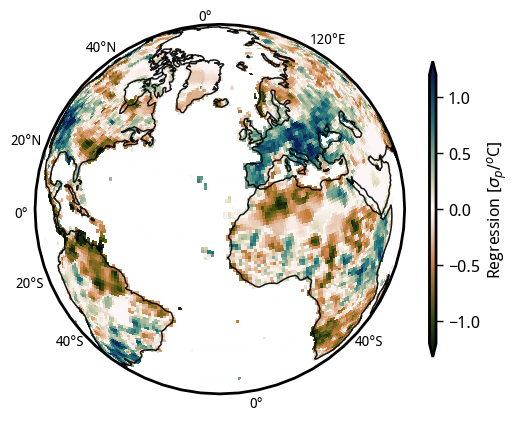

In [427]:
# fig = plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=-60))
end_year = float(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
out30.regr.sel(ey = end_year).plot(vmin=-1.2, cmap=cmocean.cm.tarn, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='Regression [$\sigma_{p}/^{o}$C]'))
# sst_obs_det.sel(time = slice(str(int(end_year) - 30), str(int(end_year)))).mean('time').plot(vmin=-0.1, cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.7, label='SST anomaly [$^{o}$C]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.pval.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

In [313]:
from eofs.xarray import Eof

In [271]:
def get_leading_eof_physical(input):
    solver = Eof(input)
    eof1 = solver.eofs(neofs=1)
    pc1 = solver.pcs(npcs=1)
    variance1 = solver.varianceFraction(neigs=1)
    print(variance1)
    return eof1*pc1.std('time') * (pc1.mean('time')/np.abs(pc1.mean('time'))), variance1.values[0]*100

<xarray.DataArray 'variance_fractions' (mode: 1)>
array([0.33872563], dtype=float32)
Coordinates:
  * mode     (mode) int64 0
Attributes:
    long_name:  variance_fractions


Text(0.5, 1.0, '')

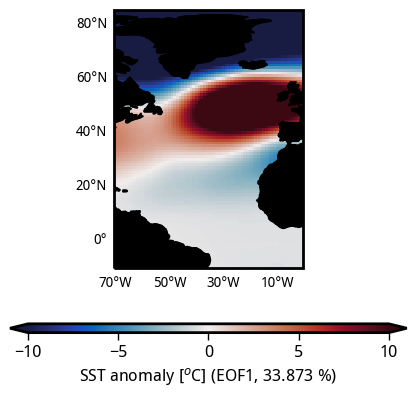

In [452]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=300))
end_year = float(reg30.where(reg30 == reg30.min('ey'), drop=True).ey)
# eof_phys, exp_var = get_leading_eof_physical(sst_obs_det.sel(time = slice(str(int(end_year) - 30), str(int(end_year)))).sel(lat = slice(50,-50), lon = slice(120, 290)))
# eof_phys, exp_var = get_leading_eof_physical(sst_obs_det.sel(time = slice(str(int(end_year) - 30), str(int(end_year)))).sel(lat = slice(50,-50), lon = slice(290, 360)))
eof_phys, exp_var = get_leading_eof_physical(zg500_rean_det.sel(time = slice(str(int(end_year) - 30), str(int(end_year)))).sel(lat = slice(-10,85), lon = slice(290, 360)))
# sst_obs_det.sel(time = slice(str(int(end_year) - 30), str(int(end_year)))).mean('time').plot(vmin=-0.1, cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.7, label='SST anomaly [$^{o}$C]'))
(eof_phys).plot(vmin=-10, cmap=cmocean.cm.balance, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=45, label='SST anomaly [$^{o}$C]' + f' (EOF1, {np.round(float(exp_var), 3)} %)'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.pval.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
ax.add_feature(cfeature.LAND, zorder=1, color='k')
plt.title('')

Text(0.5, 1.0, '')

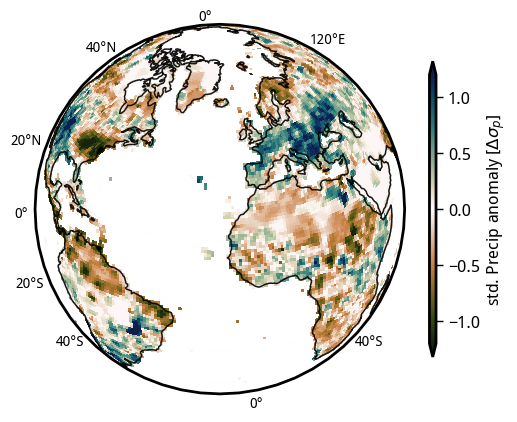

In [396]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=-60))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
precip_obs_std.where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-1.2, cmap=cmocean.cm.tarn, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='std. Precip anomaly [$\Delta \sigma_p$]'))
# (psl_rean_det/100).where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot.contour(vmin=-1.2, colors='k', transform=ccrs.PlateCarree(central_longitude=0))
# (wind_rean_det).where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').isel(lon = slice(0, -1, 4), lat = slice(0, -1, 4)).plot.quiver(x='lon', y='lat', u='uwnd', v='vwnd', color='dimgray', linewidths=1, scale=25, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta wind-speed$ [m/s]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

Text(0.5, 1.0, '')

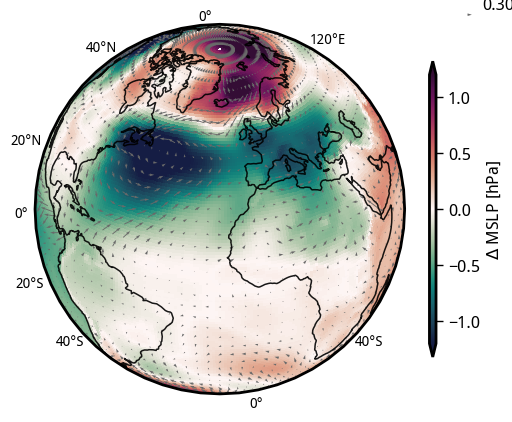

In [428]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=230, central_latitude=20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=-60))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
(psl_rean_det/100).where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-1.2, cmap=cmocean.cm.curl, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta$ MSLP [hPa]'))
(wind_rean_det).where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').isel(lon = slice(0, -1, 4), lat = slice(0, -1, 4)).plot.quiver(x='lon', y='lat', u='uwnd', v='vwnd', color='dimgray', linewidths=1, scale=25, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta wind-speed$ [m/s]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

Text(0.5, 1.0, '')

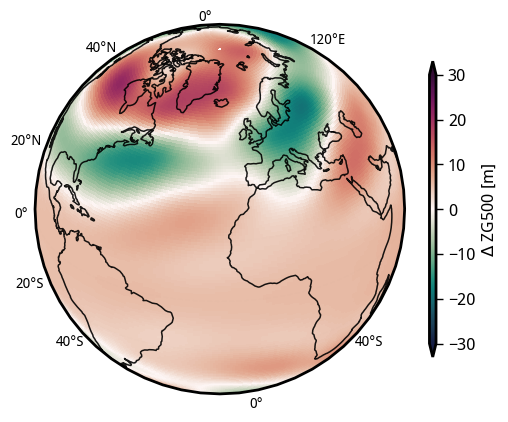

In [429]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=230, central_latitude=20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
(zg500_rean_det).where(nino34_obs > nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-30, cmap=cmocean.cm.curl, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta$ ZG500 [m]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

Text(0.5, 1.0, '')

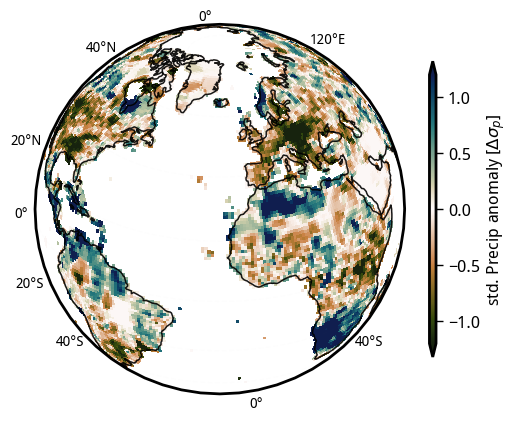

In [430]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=230, central_latitude=20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
precip_obs_std.where(nino34_obs < -nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-1.2, cmap=cmocean.cm.tarn, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='std. Precip anomaly [$\Delta \sigma_p$]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

Text(0.5, 1.0, '')

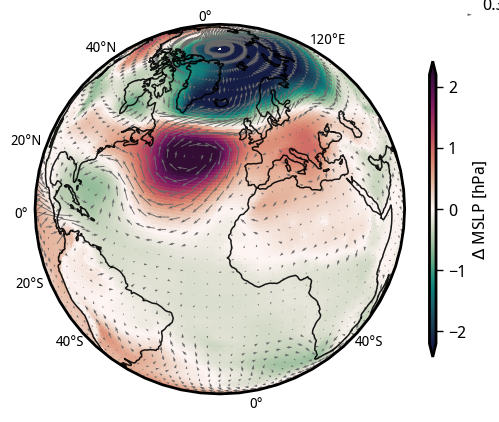

In [431]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=230, central_latitude=20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
(psl_rean_det/100).where(nino34_obs < -nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-2.2, cmap=cmocean.cm.curl, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta$ MSLP [hPa]'))
(wind_rean_det).where(nino34_obs < -nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').isel(lon = slice(0, -1, 4), lat = slice(0, -1, 4)).plot.quiver(x='lon', y='lat', u='uwnd', v='vwnd', color='dimgray', scale=25, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta wind-speed$ [m/s]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')

Text(0.5, 1.0, '')

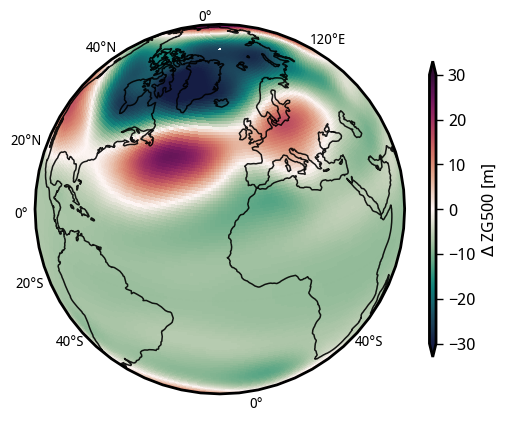

In [432]:
# fig = plt.figure(figsize=(12,6))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=160, central_latitude=-20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=230, central_latitude=20))
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=290, central_latitude=-10))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=340, central_latitude=30))
end_year = int(reg30.where(reg30 == reg30.max('ey'), drop=True).ey)
(zg500_rean_det).where(nino34_obs < -nino34_obs.std('time')).sel(time = slice(str(end_year - 30), str(end_year))).mean('time').plot(vmin=-30, cmap=cmocean.cm.curl, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='vertical', shrink=0.8, aspect=45, label='$\Delta$ ZG500 [m]'))
# xx, yy = np.meshgrid(out30_rean.lon, out30_rean.lat)
# zz = np.ma.masked_less_equal(out30_rean.regr.where(reg30 == reg30.min('ey'), drop=True).squeeze('ey'), 0.05)
# plt.pcolor(xx, yy, zz, hatch='////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
plt.title('')